In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
plt.rcParams["figure.dpi"] = 100

In [ ]:
import os
df = pd.read_csv("CC GENERAL.csv")#read the csv
print(df.shape) #shows rows and column
df.head(10) #the first 10 rows

(8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.00,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12
5,C10006,1809.828751,1.000000,1333.28,0.00,1333.28,0.000000,0.666667,0.000000,0.583333,0.000000,0,8,1800.0,1400.057770,2407.246035,0.000000,12
6,C10007,627.260806,1.000000,7091.01,6402.63,688.38,0.000000,1.000000,1.000000,1.000000,0.000000,0,64,13500.0,6354.314328,198.065894,1.000000,12
7,C10008,1823.652743,1.000000,436.20,0.00,436.20,0.000000,1.000000,0.000000,1.000000,0.000000,0,12,2300.0,679.065082,532.033990,0.000000,12
8,C10009,1014.926473,1.000000,861.49,661.49,200.00,0.000000,0.333333,0.083333,0.250000,0.000000,0,5,7000.0,688.278568,311.963409,0.000000,12
9,C10010,152.225975,0.545455,1281.60,1281.60,0.00,0.000000,0.166667,0.166667,0.000000,0.000000,0,3,11000.0,1164.770591,100.302262,0.000000,12


## 1. Look at the data

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHA

In [ ]:
df.isna().sum()[lambda s: s > 0]#shows the columns with missing values more than 0

CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64

In [8]:
df.describe().T[["mean", "50%", "max"]]

,mean,50%,max
BALANCE,1564.474828,873.385231,19043.13856
BALANCE_FREQUENCY,0.877271,1.000000,1.00000
PURCHASES,1003.204834,361.280000,49039.57000
ONEOFF_PURCHASES,592.437371,38.000000,40761.25000
INSTALLMENTS_PURCHASES,411.067645,89.000000,22500.00000
CASH_ADVANCE,978.871112,0.000000,47137.21176
PURCHASES_FREQUENCY,0.490351,0.500000,1.00000
ONEOFF_PURCHASES_FREQUENCY,0.202458,0.083333,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,0.364437,0.166667,1.00000
CASH_ADVANCE_FREQUENCY,0.135144,0.000000,1.50000


## 2. cleaning

In [20]:
data = df.drop(columns=["CUST_ID"])   # id, not a feature

# median fill because of the skew
data = data.fillna(data.median())#fills the missing values with the median of the columns
print("missing left:", data.isna().sum().sum())#shows the total missing values left

missing left: 0


9 skewed columns: ['BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'PAYMENTS', 'MINIMUM_PAYMENTS']


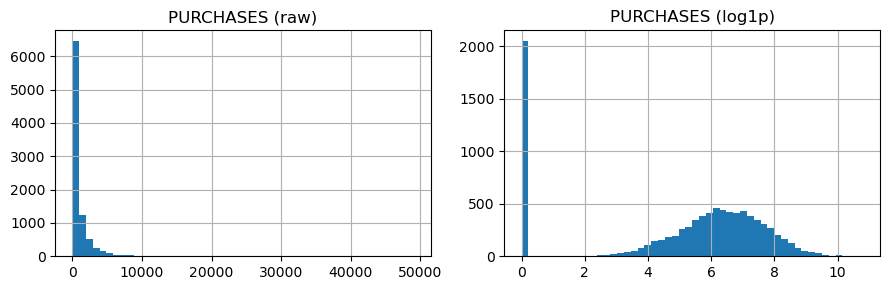

In [21]:
#finding skewed columns
skewed = [c for c in data.columns if data[c].skew() > 2]
print(len(skewed), "skewed columns:", skewed)

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
data["PURCHASES"].hist(bins=50, ax=ax[0])#bins divides the data in 50 intervals 
ax[0].set_title("PURCHASES (raw)")
np.log1p(data["PURCHASES"]).hist(bins=50, ax=ax[1])#log transformation makes the larger values smaller and makes the distribution more balanced
ax[1].set_title("PURCHASES (log1p)")
plt.tight_layout()
plt.show()

In [22]:
data_log = data.copy()
data_log[skewed] = np.log1p(data_log[skewed])

scaler = StandardScaler()
X = scaler.fit_transform(data_log)#makes the columns easier to compare
X.shape

(8950, 17)

## 3. K-Means: choosing k

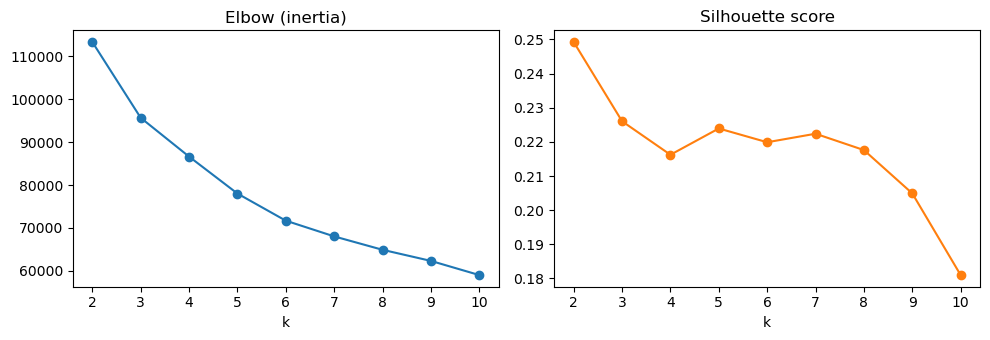

In [26]:
ks = range(2, 11)
inertias, sils = [], []
for k in ks:
    km = KMeans(
        n_clusters=k, 
        n_init=10, 
        random_state=RANDOM_STATE
        ).fit(X)
    inertias.append(km.inertia_)
    # silhouette on a sample, full set is slow-ish
    sils.append(silhouette_score(
        X,
        km.labels_, 
        sample_size=3000, 
        random_state=RANDOM_STATE)
        )

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(ks, inertias, "o-")
ax[0].set_title("Elbow (inertia)")
ax[0].set_xlabel("k")

ax[1].plot(ks, sils, "o-", color="tab:orange")
ax[1].set_title("Silhouette score")
ax[1].set_xlabel("k")
plt.tight_layout()
plt.show()

In [28]:
K = 3

km = KMeans(
    n_clusters=K,
    n_init=10,
    random_state=RANDOM_STATE
).fit(X)

df["cluster"] = km.labels_

df["cluster"].value_counts().sort_index()

cluster
0    2881
1    2894
2    3175
Name: count, dtype: int64

## 4. Clusters

In [30]:
# profile using the original values so the numbers mean something
profile = df.drop(columns=["CUST_ID"]).groupby("cluster").mean().round(2)
profile.T

cluster,0,1,2
BALANCE,2358.75,231.98,2058.31
BALANCE_FREQUENCY,0.92,0.72,0.98
PURCHASES,103.20,468.47,2307.28
ONEOFF_PURCHASES,84.50,179.14,1430.06
INSTALLMENTS_PURCHASES,18.74,289.82,877.58
CASH_ADVANCE,2157.30,32.74,771.96
PURCHASES_FREQUENCY,0.07,0.52,0.84
ONEOFF_PURCHASES_FREQUENCY,0.04,0.08,0.46
PURCHASES_INSTALLMENTS_FREQUENCY,0.03,0.43,0.62
CASH_ADVANCE_FREQUENCY,0.30,0.01,0.10


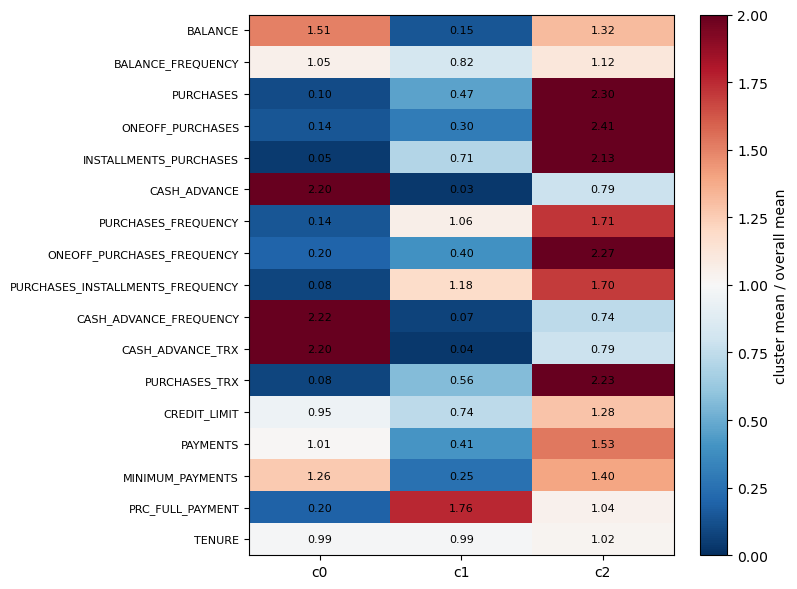

In [32]:
# same thing but relative to the overall mean
rel = profile / df.drop(columns=["CUST_ID", "cluster"]).mean()

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    rel.T.values,
    aspect="auto",
    cmap="RdBu_r",
    vmin=0,
    vmax=2
)

ax.set_xticks(range(K))
ax.set_xticklabels([f"c{i}" for i in range(K)])

ax.set_yticks(range(rel.shape[1]))
ax.set_yticklabels(rel.columns, fontsize=8)

for i in range(rel.shape[1]):
    for j in range(K):
        value = rel.T.values[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8)

plt.colorbar(im, label="cluster mean / overall mean")
plt.tight_layout()
plt.show()

**My interpretation**

- cluster 0: Cash-advance users - These customers have high cash advance usage and frequency, but very low purchase activity compared to the overall average.
- cluster 1: Low-activity customers - These customers have low spending, low balances and very little cash advance usage. However, they have a higher full-payment percentage than the overall average.
- cluster 2: Big spenders - These customers have high purchase amounts and purchase frequencies, including both one-time and installment purchases. They also have higher payment amounts and balances than the overall average.

## 5. PCA

17 features is hard to look at, and a lot of them are correlated. PCA should be able to squeeze this down.

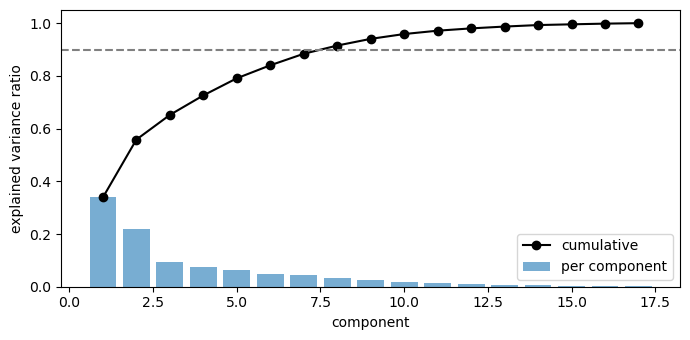

8 components keep 90% of the variance (out of 17)
PC1 + PC2 = 0.558


In [33]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(range(1, len(evr) + 1), evr, alpha=0.6, label="per component")
ax.plot(range(1, len(evr) + 1), cum, "o-", color="k", label="cumulative")
ax.axhline(0.9, ls="--", color="grey")
ax.set_xlabel("component"); ax.set_ylabel("explained variance ratio"); ax.legend()
plt.tight_layout(); plt.show()

n90 = int(np.argmax(cum >= 0.9)) + 1
print(f"{n90} components keep 90% of the variance (out of {X.shape[1]})")
print("PC1 + PC2 =", round(cum[1], 3))

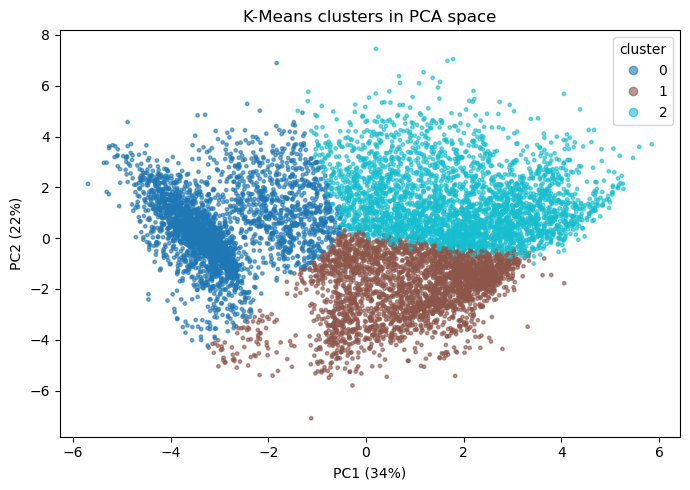

In [34]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X2 = pca.fit_transform(X)

plt.figure(figsize=(7, 5))
sc = plt.scatter(X2[:, 0], X2[:, 1], c=df["cluster"], cmap="tab10", s=6, alpha=0.6)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
plt.title("K-Means clusters in PCA space")
plt.legend(*sc.legend_elements(), title="cluster")
plt.tight_layout(); plt.show()

In [37]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=data.columns,
    columns=["PC1", "PC2"]
)
loadings.sort_values(
    "PC1", 
    key=abs, 
    ascending=False
    ).round(2)

,PC1,PC2
PURCHASES_TRX,0.38,0.17
PURCHASES_FREQUENCY,0.37,0.12
PURCHASES,0.36,0.12
INSTALLMENTS_PURCHASES,0.33,0.07
PURCHASES_INSTALLMENTS_FREQUENCY,0.31,0.07
CASH_ADVANCE,-0.30,0.26
CASH_ADVANCE_TRX,-0.28,0.28
CASH_ADVANCE_FREQUENCY,-0.25,0.27
ONEOFF_PURCHASES_FREQUENCY,0.22,0.22
ONEOFF_PURCHASES,0.21,0.21


In [36]:
Xr = PCA(n_components=n90, random_state=RANDOM_STATE).fit_transform(X)
km_r = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Xr)

from sklearn.metrics import adjusted_rand_score
print("adjusted rand index (full vs reduced):", round(adjusted_rand_score(km.labels_, km_r.labels_), 3))
print("features:", X.shape[1], "->", Xr.shape[1])

adjusted rand index (full vs reduced): 0.976
features: 17 -> 8
